# México y China: regresión demográfica y extrapolación

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Pregunta y plan
Se estudian por separado nacimientos y defunciones de México y China. Se reserva la última
década histórica para comparar una recta, un polinomio cuadrático, Random Forest y persistencia.
Después se reajustan los modelos con todos los históricos para ilustrar extrapolaciones hasta 2100.
Las curvas de OWID/ONU son **proyecciones externas**, no valores verdaderos del futuro.
[Nacimientos](https://ourworldindata.org/grapher/number-of-births-per-year) ·
[Defunciones](https://ourworldindata.org/grapher/number-of-deaths-per-year).

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone
nacimientos = leer_owid("number-of-births-per-year")
defunciones = leer_owid("number-of-deaths-per-year")
columnas_b = {"births__sex_all__age_all__variant_estimates": "births",
              "births__sex_all__age_all__variant_medium__projected": "births_owid"}
columnas_d = {"deaths__sex_all__age_all__variant_estimates": "deaths",
              "deaths__sex_all__age_all__variant_medium__projected": "deaths_owid"}
datos = nacimientos.rename(columns=columnas_b).merge(
    defunciones.rename(columns=columnas_d).drop(columns="code"),
    on=["entity", "year"], validate="one_to_one")
datos = datos.loc[datos.entity.isin(["Mexico", "China"])].sort_values(["entity", "year"])
display(datos.head())
assert not datos.duplicated(["entity", "year"]).any()

,entity,code,year,births,births_owid,deaths,deaths_owid
6644,China,CHN,1950,22293376.0,NaN,12564023.0,NaN
6645,China,CHN,1951,22144814.0,NaN,12411701.0,NaN
6646,China,CHN,1952,25496318.0,NaN,12459848.0,NaN
6647,China,CHN,1953,24139416.0,NaN,12309525.0,NaN
6648,China,CHN,1954,25438544.0,NaN,12145578.0,NaN


## 2. Comparar volúmenes y tasas
Un mayor número de nacimientos puede reflejar mayor población. La tabla incluye también
tasas por mil habitantes del dataset preparado y las variables de salud e ingreso, en años comunes.

,birth_rate_per_1000,death_rate_per_1000,percentage_health,gdp
entity,,,,
China,12.13,6.67,4.57,11757.05
Mexico,19.88,5.99,5.40,20717.62


CSV guardado: U3_1_modelos_ml/data/processed/demografia_china_mexico_completo.csv (46 filas)


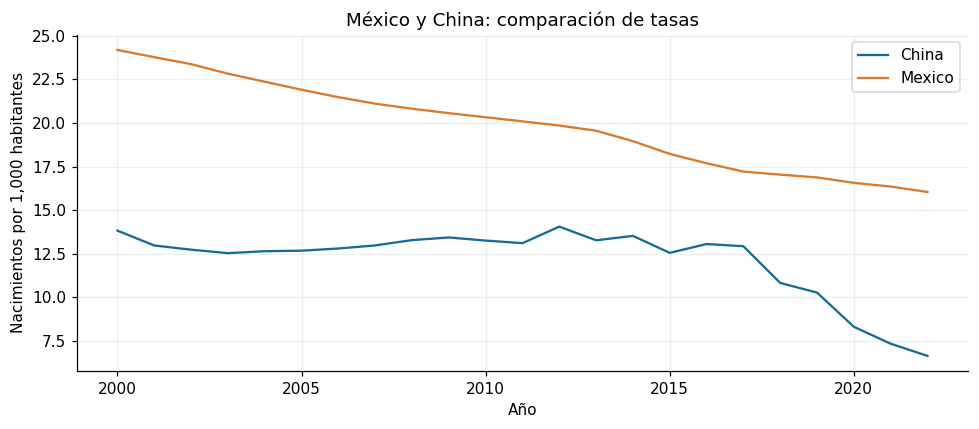

In [3]:
demografia = pd.read_csv(SALIDA / "demografia_owid_2000_2022.csv")
integrado = pd.read_csv(U3 / "data/dataset_health_gdp_demografia_final.csv")
comparacion = demografia.merge(integrado[["entity", "year", "percentage_health", "gdp"]],
                              on=["entity", "year"], validate="one_to_one")
comparacion = comparacion.loc[comparacion.entity.isin(["Mexico", "China"])].copy()
display(comparacion.groupby("entity")[["birth_rate_per_1000", "death_rate_per_1000", "percentage_health", "gdp"]].mean().round(2))
guardar_tabla(comparacion, "demografia_china_mexico_completo.csv")
for pais, grupo in comparacion.groupby("entity"):
    plt.plot(grupo.year, grupo.birth_rate_per_1000, label=pais)
plt.xlabel("Año"); plt.ylabel("Nacimientos por 1,000 habitantes")
plt.title("México y China: comparación de tasas"); plt.legend()
guardar_figura("U3_2_china_mexico_tasas")

## 3. Evaluación temporal 2014-2023
Entrenamiento: 1950-2013. Prueba: 2014-2023. Se fija la configuración antes de observar
las métricas de prueba. Persistencia repite el último valor de 2013 para los diez años;
es una línea base de origen fijo. Los errores se expresan en número de eventos, por lo
que no se comparan directamente las magnitudes entre países de tamaños distintos.

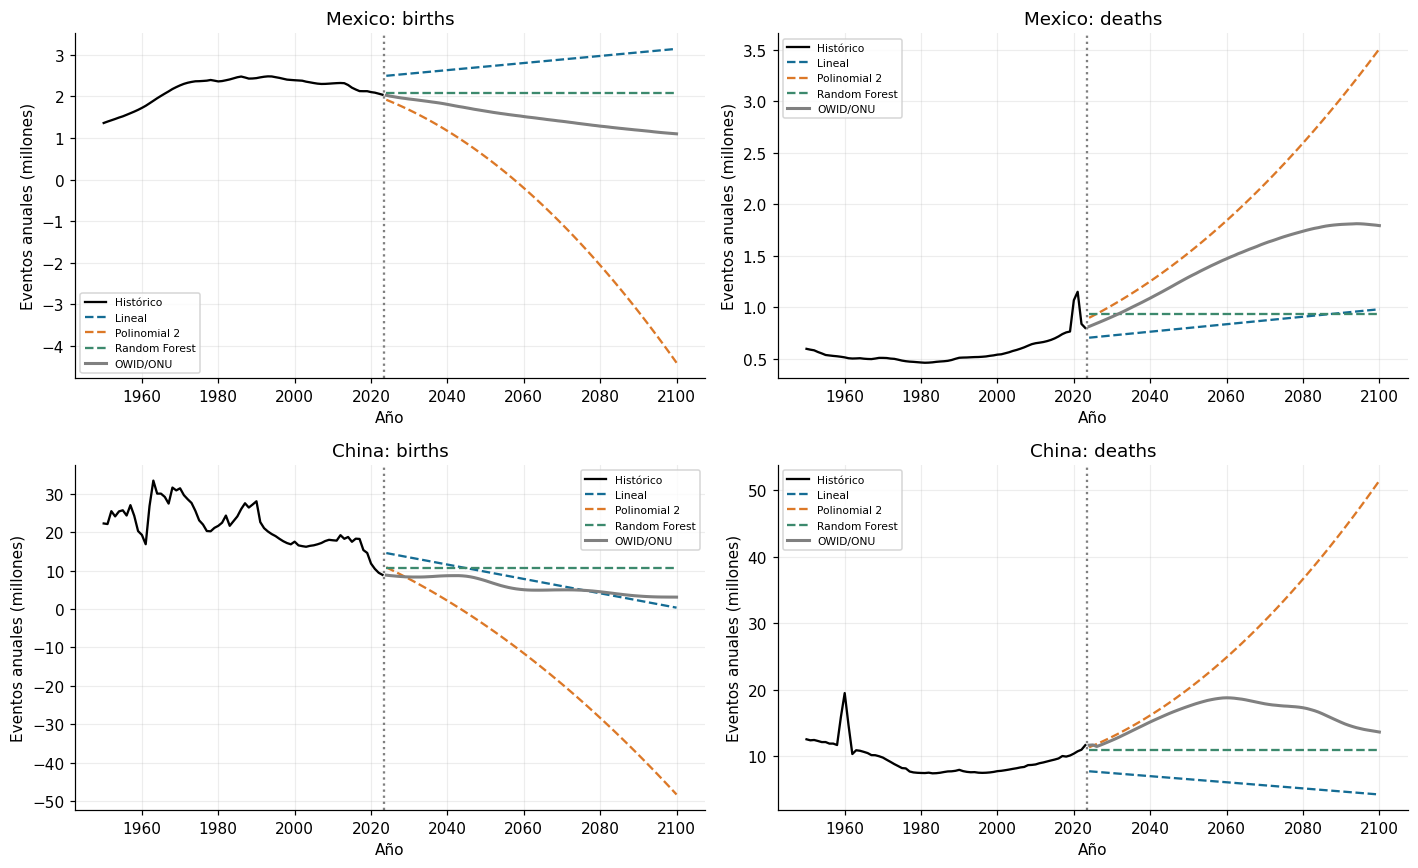

,entity,variable,modelo,MAE,RMSE
0,Mexico,births,Persistencia,184643.6,195852.3
1,Mexico,births,Lineal,567420.8,576893.9
2,Mexico,births,Polinomial 2,131459.9,139978.9
3,Mexico,births,Random Forest,184161.5,195397.8
4,Mexico,deaths,Persistencia,150020.1,213194.6
...,...,...,...,...,...
11,China,births,Random Forest,4117286.6,5479288.1
12,China,deaths,Persistencia,1023934.8,1229561.8
13,China,deaths,Lineal,4042487.2,4145434.6
14,China,deaths,Polinomial 2,255277.0,327236.2


CSV guardado: U3_1_modelos_ml/data/processed/regresion_china_mexico_metricas.csv (16 filas)
CSV guardado: U3_1_modelos_ml/data/processed/regresion_china_mexico_2100.csv (924 filas)


In [4]:
def candidatos():
    return {"Lineal": make_pipeline(StandardScaler(), LinearRegression()),
            "Polinomial 2": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LinearRegression()),
            "Random Forest": RandomForestRegressor(n_estimators=180, min_samples_leaf=2, random_state=82005)}
filas, predicciones_futuras = [], []
modelos_finales = {}
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
for i, pais in enumerate(["Mexico", "China"]):
    pais_datos = datos.loc[datos.entity.eq(pais)]
    for j, variable in enumerate(["births", "deaths"]):
        historico = pais_datos.dropna(subset=[variable]).copy()
        train = historico.loc[historico.year.le(2013)]
        test = historico.loc[historico.year.between(2014, 2023)]
        assert train.year.max() < test.year.min() and len(test) == 10
        pred_base = np.repeat(train[variable].iloc[-1], len(test))
        todos = {"Persistencia": pred_base}
        eje = ejes[i, j]
        eje.plot(historico.year, historico[variable]/1e6, color="black", label="Histórico")
        futuro = pd.DataFrame({"year": np.arange(2024, 2101)})
        referencia = pais_datos.set_index("year")[f"{variable}_owid"].reindex(futuro.year).to_numpy()
        for nombre, plantilla in candidatos().items():
            modelo_prueba = clone(plantilla).fit(train[["year"]], train[variable])
            todos[nombre] = modelo_prueba.predict(test[["year"]])
            final = clone(plantilla).fit(historico[["year"]], historico[variable])
            modelos_finales[(pais, variable, nombre)] = final
            pred = final.predict(futuro)
            eje.plot(futuro.year, pred/1e6, label=nombre, linestyle="--")
            for anio, valor, owid in zip(futuro.year, pred, referencia):
                predicciones_futuras.append({"entity": pais, "year": int(anio), "variable": variable,
                                            "modelo": nombre, "estimacion": float(valor), "escenario_owid": float(owid)})
        for nombre, pred in todos.items():
            filas.append({"entity": pais, "variable": variable, "modelo": nombre,
                          "MAE": mean_absolute_error(test[variable], pred),
                          "RMSE": np.sqrt(mean_squared_error(test[variable], pred))})
        eje.plot(futuro.year, referencia/1e6, color="gray", lw=2, label="OWID/ONU")
        eje.axvline(2023.5, color="gray", ls=":")
        eje.set(title=f"{pais}: {variable}", xlabel="Año", ylabel="Eventos anuales (millones)")
        eje.legend(fontsize=7)
guardar_figura("U3_2_china_mexico_modelos")
metricas = pd.DataFrame(filas)
proyecciones = pd.DataFrame(predicciones_futuras)
display(metricas.round(1))
guardar_tabla(metricas, "regresion_china_mexico_metricas.csv")
guardar_tabla(proyecciones, "regresion_china_mexico_2100.csv")

## 4. Respuestas a la comparación
**¿Los dos países tienen el mismo comportamiento?** No; los conteos y las tasas describen
escalas y trayectorias distintas. Las curvas y la tabla permiten comparar cada variable sin
atribuir todos los cambios a una sola causa. **¿Qué modelo funciona mejor?** La tabla siguiente
identifica el menor MAE en la década reservada para cada par país-variable, incluyendo la base.
Eso responde una pregunta histórica concreta, no certifica las proyecciones de fin de siglo.

In [5]:
mejores = metricas.loc[metricas.groupby(["entity", "variable"]).MAE.idxmin()].reset_index(drop=True)
display(mejores.round(1))
negativos = proyecciones.groupby(["entity", "variable", "modelo"]).estimacion.min().lt(0)
print("Combinaciones con extrapolaciones negativas:", int(negativos.sum()))
display(proyecciones.loc[proyecciones.year.isin([2030, 2050, 2100])].round(0))

,entity,variable,modelo,MAE,RMSE
0,China,births,Polinomial 2,2788681.0,3472423.1
1,China,deaths,Polinomial 2,255277.0,327236.2
2,Mexico,births,Polinomial 2,131459.9,139978.9
3,Mexico,deaths,Polinomial 2,87502.0,159515.4


Combinaciones con extrapolaciones negativas: 2


,entity,year,variable,modelo,estimacion,escenario_owid
6,Mexico,2030,births,Lineal,2543559.0,1934285.0
26,Mexico,2050,births,Lineal,2713775.0,1643767.0
76,Mexico,2100,births,Lineal,3139315.0,1098210.0
83,Mexico,2030,births,Polinomial 2,1672155.0,1934285.0
103,Mexico,2050,births,Polinomial 2,543760.0,1643767.0
...,...,...,...,...,...,...
796,China,2050,deaths,Polinomial 2,20134799.0,17526300.0
846,China,2100,deaths,Polinomial 2,51416093.0,13655445.0
853,China,2030,deaths,Random Forest,10938994.0,12415078.0
873,China,2050,deaths,Random Forest,10938994.0,17526300.0


## 5. Conclusión
Una recta impone una dirección constante y un polinomio puede crecer o caer fuera de rangos
plausibles. Un bosque de árboles devuelve respuestas constantes al extrapolar más allá del
último umbral del año. No se recortan valores negativos para hacerlos parecer razonables:
se muestran como evidencia de los límites del método. Las proyecciones demográficas de la ONU
incorporan componentes y supuestos que estos modelos univariados no representan.